In [1]:
if(!require("pacman")) install.packages("pacman")
pacman::p_load(knitr, arrow, gt, ggsci, patchwork, binom, tidyverse)

Loading required package: pacman



# Data

I only need a handful of columns for this one, so I take them straight off the read.

In [2]:
ed_data <- read_parquet("../ANALYSIS/ed_single.parquet") |>
  # Ill only keep some columns for this analysis
  select(
    stay_id,
    disposition,
    acuity,
    rhythm,
    pre_gsn_count,
    med_gsn_count,
    dead_on_day,
    age,
    gender,
    race,
   
    length_of_stay,
    icd_chapter,
    cluster,
    nyu,
    res,
    acuity_out
  )

print(dim(ed_data))

[1] 201106     16


## Check

Before anything else, check the numbers this notebook has to agree with. I also rebuild `res` from the rule as it is written, to be sure I am reasoning about the same thing the column contains.

In [3]:
n_tot <- nrow(ed_data)
n_nyu <- sum(ed_data$nyu == 1)
n_res <- sum(ed_data$res == 1)
n_acu <- sum(ed_data$acuity_out == 1)

# The three dispositions the Resources rule removes
excluded_disp <- c("ADMITTED", "TRANSFER", "EXPIRED")

n_bad <- sum(ed_data$res == 1 & ed_data$disposition %in% excluded_disp)

# Rebuild res from the rule and see whether it lands on the published column
res_rebuilt <- as.integer(
  !ed_data$disposition %in% excluded_disp &
    is.na(ed_data$rhythm) &
    is.na(ed_data$pre_gsn_count) &
    ed_data$dead_on_day == "No"
)

checks <- tibble(
  check = c(
    "Visits = 201,106",
    "Diagnosis = 68,173",
    "Resources = 48,181",
    "Triage-Acuity = 15,716",
    "No ADMITTED / TRANSFER / EXPIRED visit carries the Resources flag",
    "res rebuilt from the rule matches the published column"
  ),
  observed = c(
    format(n_tot, big.mark = ","),
    format(n_nyu, big.mark = ","),
    format(n_res, big.mark = ","),
    format(n_acu, big.mark = ","),
    paste(n_bad, "flagged"),
    paste(sum(res_rebuilt != ed_data$res), "mismatches")
  ),
  pass = c(
    n_tot == 201106,
    n_nyu == 68173,
    n_res == 48181,
    n_acu == 15716,
    n_bad == 0,
    all(res_rebuilt == ed_data$res)
  )
)

checks |> kable()

if (any(!checks$pass)) stop("A check failed - find out why before going any further.")
print("All checks pass.")



|check                                                             |observed     |pass |
|:-----------------------------------------------------------------|:------------|:----|
|Visits = 201,106                                                  |201,106      |TRUE |
|Diagnosis = 68,173                                                |68,173       |TRUE |
|Resources = 48,181                                                |48,181       |TRUE |
|Triage-Acuity = 15,716                                            |15,716       |TRUE |
|No ADMITTED / TRANSFER / EXPIRED visit carries the Resources flag |0 flagged    |TRUE |
|res rebuilt from the rule matches the published column            |0 mismatches |TRUE |

[1] "All checks pass."


All six pass. The last one is the useful one: rebuilding `res` from the rule reproduces the published column exactly, zero mismatches over 201,106 rows. So for any disposition the rule leaves eligible, `res` *is* 'no rhythm charted and no medication dispensed and alive that day' - nothing else is going on inside it.

One field to be careful with, because the names are similar. `pre_gsn_count` comes from `pyxis`, medication actually dispensed from the cabinet during the ED stay, and that is the field the Resources rule uses. `med_gsn_count` comes from `medrecon`, the patient's pre-existing home medication list taken at reconciliation, and no algorithm uses it at all.

In [4]:
ed_data |>
  summarise(
    `pyxis - nothing dispensed in ED (%)`   = 100 * mean(is.na(pre_gsn_count)),
    `medrecon - no home med list (%)`       = 100 * mean(is.na(med_gsn_count))
  ) |>
  kable()



| pyxis - nothing dispensed in ED (%)| medrecon - no home med list (%)|
|-----------------------------------:|-------------------------------:|
|                            31.28251|                        35.48974|

Different fields, different missingness. Only the first one enters the rule.

# Disposition

`disposition` has eight values and no missing. Only three of them are excluded by the Resources rule, so I want to see what the other five contain.

In [5]:
lbcc_disp <- c("LEFT WITHOUT BEING SEEN", "ELOPED", "LEFT AGAINST MEDICAL ADVICE")

disp_labels <- c(
  "HOME"                        = "Home",
  "ADMITTED"                    = "Admitted",
  "TRANSFER"                    = "Transfer",
  "EXPIRED"                     = "Expired",
  "LEFT WITHOUT BEING SEEN"     = "Left without being seen",
  "ELOPED"                      = "Eloped",
  "LEFT AGAINST MEDICAL ADVICE" = "Left against medical advice",
  "OTHER"                       = "Other"
)

ed_data <- ed_data |>
  mutate(
    disp_l    = unname(disp_labels[disposition]),
    lbcc      = disposition %in% lbcc_disp,
    no_rhythm = is.na(rhythm),
    no_med    = is.na(pre_gsn_count)
  )

disp_tab <- ed_data |>
  count(disp_l, name = "N") |>
  left_join(
    ed_data |> distinct(disp_l, disposition),
    by = "disp_l"
  ) |>
  mutate(
    `%` = sprintf("%.2f", 100 * N / n_tot),
    `Under the Resources rule` = case_when(
      disposition %in% excluded_disp ~ "Excluded",
      disposition %in% lbcc_disp     ~ "Eligible - left before completing care",
      disposition == "HOME"          ~ "Eligible - completed visit, discharged",
      TRUE                           ~ "Eligible - destination not specified"
    )
  ) |>
  arrange(desc(N)) |>
  select(Disposition = disp_l, N, `%`, `Under the Resources rule`)

disp_tab |> kable()



|Disposition                 |      N|%     |Under the Resources rule               |
|:---------------------------|------:|:-----|:--------------------------------------|
|Home                        | 121407|60.37 |Eligible - completed visit, discharged |
|Admitted                    |  68847|34.23 |Excluded                               |
|Transfer                    |   3141|1.56  |Excluded                               |
|Left without being seen     |   2597|1.29  |Eligible - left before completing care |
|Other                       |   2344|1.17  |Eligible - destination not specified   |
|Eloped                      |   1913|0.95  |Eligible - left before completing care |
|Left against medical advice |    756|0.38  |Eligible - left before completing care |
|Expired                     |    101|0.05  |Excluded                               |

In [6]:
print(paste0(
  "Excluded by the rule: ",
  format(sum(ed_data$disposition %in% excluded_disp), big.mark = ","),
  " visits (",
  sprintf("%.2f", 100 * mean(ed_data$disposition %in% excluded_disp)),
  "%). Everything else stays eligible."
))

[1] "Excluded by the rule: 72,089 visits (35.85%). Everything else stays eligible."


756 visits left against medical advice, 2,597 left without being seen and 1,913 eloped. None of those are excluded. Every one of them is still eligible to be labelled potentially avoidable.

# Flag rate by disposition

How each algorithm treats each disposition. Flag rate is the percentage of visits in that category the algorithm calls potentially avoidable. Confidence intervals on the Resources column, since that is the one at issue.

In [7]:
prop_fn <- function(x, n) {
  ci <- binom::binom.confint(sum(x), n, method = "agresti-coull")
  sprintf("%.1f [%.1f-%.1f]",
          ci$mean * 100,
          max(0, ci$lower) * 100,   # agresti-coull runs below zero when there are no events
          min(1, ci$upper) * 100)
}

flag_tab <- ed_data |>
  group_by(disp_l) |>
  summarise(
    N               = n(),
    Diagnosis       = sprintf("%.1f", 100 * mean(nyu == 1)),
    Resources       = prop_fn(res == 1, n()),
    `Triage-Acuity` = sprintf("%.1f", 100 * mean(acuity_out == 1)),
    `Any of three`  = sprintf("%.1f", 100 * mean(nyu == 1 | res == 1 | acuity_out == 1)),
    res_sort        = mean(res == 1),
    .groups = "drop"
  ) |>
  arrange(desc(res_sort)) |>
  select(Disposition = disp_l, N, Diagnosis, Resources, `Triage-Acuity`, `Any of three`)

flag_tab |> kable()

flag_tab |>
  gt() |>
  tab_spanner(
    label   = "Flagged potentially avoidable (%)",
    columns = c(Diagnosis, Resources, `Triage-Acuity`, `Any of three`)
  ) |>
  tab_footnote(
    footnote  = "Resources shown with 95% Agresti-Coull confidence interval.",
    locations = cells_column_labels(columns = Resources)
  ) |>
  gtsave(filename = "s4_table_1.docx")



|Disposition                 |      N|Diagnosis |Resources        |Triage-Acuity |Any of three |
|:---------------------------|------:|:---------|:----------------|:-------------|:------------|
|Left without being seen     |   2597|70.3      |98.0 [97.4-98.5] |14.8          |99.3         |
|Eloped                      |   1913|44.6      |65.1 [63.0-67.2] |11.7          |83.0         |
|Left against medical advice |    756|39.6      |43.5 [40.0-47.1] |1.9           |66.4         |
|Home                        | 121407|44.7      |35.6 [35.3-35.9] |12.2          |69.4         |
|Other                       |   2344|18.0      |34.9 [33.0-36.9] |3.1           |41.6         |
|Admitted                    |  68847|14.5      |0.0 [0.0-0.0]    |0.3           |14.8         |
|Expired                     |    101|10.9      |0.0 [0.0-4.4]    |2.0           |11.9         |
|Transfer                    |   3141|15.4      |0.0 [0.0-0.1]    |0.9           |15.9         |

The 0% for admitted, transfer and expired under Resources is forced by the rule, not a result - those three are the exclusion list. Everything underneath it is a result.

Left without being seen 98.0%, eloped 65.1%, against medical advice 43.5%, home 35.6%. Diagnosis and Triage-Acuity have nothing resembling that gradient; Triage-Acuity flags left-without-being-seen (14.8%) and home (12.2%) at almost the same rate. Whatever is happening, it is happening inside the Resources definition and not in the sample.

# Why

The three departure categories belong together - left without being seen, eloped, against medical advice. All three ended before care was finished. I'll call the group *left before completing care*.

In [8]:
print(paste0(
  "Left before completing care: ",
  format(sum(ed_data$lbcc), big.mark = ","),
  " visits (", sprintf("%.2f", 100 * mean(ed_data$lbcc)), "% of the sample), of which ",
  format(sum(ed_data$lbcc & ed_data$res == 1), big.mark = ","),
  " carry the Resources flag - ",
  sprintf("%.1f", 100 * sum(ed_data$lbcc & ed_data$res == 1) / n_res),
  "% of the whole Resources group."
))

[1] "Left before completing care: 5,266 visits (2.62% of the sample), of which 4,121 carry the Resources flag - 8.6% of the whole Resources group."


The rule has two data conditions in it. Take them apart and see which one is doing the work.

In [9]:
mech_of <- function(d, label) {
  tibble(
    Group                         = label,
    N                             = nrow(d),
    `No rhythm charted (%)`       = sprintf("%.2f", 100 * mean(d$no_rhythm)),
    `No medication dispensed (%)` = sprintf("%.2f", 100 * mean(d$no_med)),
    `Neither recorded (%)`        = sprintf("%.2f", 100 * mean(d$no_rhythm & d$no_med)),
    `Resources flagged (%)`       = sprintf("%.2f", 100 * mean(d$res == 1))
  )
}

pick <- function(x) ed_data |> filter(disposition == x)

mech_tab <- bind_rows(
  mech_of(pick("LEFT WITHOUT BEING SEEN"),     "Left without being seen"),
  mech_of(pick("ELOPED"),                      "Eloped"),
  mech_of(pick("LEFT AGAINST MEDICAL ADVICE"), "Left against medical advice"),
  mech_of(ed_data |> filter(lbcc),             "All three pooled"),
  mech_of(pick("HOME"),                        "Home"),
  mech_of(pick("OTHER"),                       "Other"),
  mech_of(pick("ADMITTED"),                    "Admitted")
)

mech_tab |> kable()

mech_tab |>
  gt() |>
  tab_row_group(label = "Completed the visit", rows = 5:7) |>
  tab_row_group(label = "Left before completing care", rows = 1:4) |>
  gtsave(filename = "s4_table_2.docx")



|Group                       |      N|No rhythm charted (%) |No medication dispensed (%) |Neither recorded (%) |Resources flagged (%) |
|:---------------------------|------:|:---------------------|:---------------------------|:--------------------|:---------------------|
|Left without being seen     |   2597|99.96                 |98.07                       |98.04                |98.04                 |
|Eloped                      |   1913|99.22                 |65.34                       |65.13                |65.13                 |
|Left against medical advice |    756|96.16                 |44.84                       |43.52                |43.52                 |
|All three pooled            |   5266|99.15                 |78.54                       |78.26                |78.26                 |
|Home                        | 121407|98.56                 |36.08                       |35.62                |35.62                 |
|Other                       |   2344|96.63   

The medication field does all of the work. 98.1% of left-without-being-seen visits have nothing dispensed against 36.1% of home discharges - a patient who leaves before treatment satisfies that condition by definition.

The rhythm field discriminates almost nothing. It is unrecorded in 98.6% of home visits and 94.2% of admitted ones, so it separates neither minor from major presentations nor treated from untreated. Which means that for the dispositions the rule leaves eligible, the Resources flag is very close to just meaning *no medication was dispensed*.

# Stratify by acuity

The obvious objection is that these patients were simply less sick, and the flag is picking that up. Stratifying the Resources flag rate by triage ESI settles it.

In [10]:
acuity_tab <- ed_data |>
  filter(disposition %in% c("HOME", lbcc_disp)) |>
  group_by(disp_l, acuity) |>
  summarise(N = n(), res_p = 100 * mean(res == 1), .groups = "drop") |>
  mutate(cell = sprintf("%.1f%% (n=%s)", res_p, format(N, big.mark = ",", trim = TRUE))) |>
  select(disp_l, acuity, cell) |>
  pivot_wider(names_from = disp_l, values_from = cell) |>
  arrange(acuity) |>
  mutate(across(everything(), ~ replace_na(as.character(.x), "-"))) |>
  select(
    `Triage ESI` = acuity,
    Home,
    `Left without being seen`,
    Eloped,
    `Left against medical advice`
  )

acuity_tab |> kable()



|Triage ESI |Home             |Left without being seen |Eloped          |Left against medical advice |
|:----------|:----------------|:-----------------------|:---------------|:---------------------------|
|1          |25.6% (n=3,415)  |100.0% (n=1)            |34.6% (n=52)    |24.5% (n=53)                |
|2          |32.8% (n=27,616) |96.8% (n=312)           |59.6% (n=421)   |42.3% (n=326)               |
|3          |35.0% (n=75,608) |98.2% (n=1,900)         |67.2% (n=1,216) |47.4% (n=363)               |
|4          |45.8% (n=14,378) |98.3% (n=354)           |70.0% (n=213)   |42.9% (n=14)                |
|5          |64.9% (n=390)    |96.7% (n=30)            |100.0% (n=11)   |-                           |

Among ESI 3 patients - the modal category - left without being seen is flagged 98.2% of the time against 35.0% of home discharges. Same triage urgency, and the flag rate is nearly three times higher.

That is the point of the whole notebook. The Resources flag cannot separate *needed few resources* from *received no resources*, because the trace of the second looks identical to the trace of the first.

# Figure 1

I use the JAMA palette, same as the main figures.

In [11]:
jama_palette <- ggsci::pal_jama()(7)

fig_theme <- theme_minimal() +
  theme(
    panel.grid  = element_blank(),
    axis.line   = element_line(color = "black")
  )


## Figure 1A

Flag rate by disposition, all three algorithms.

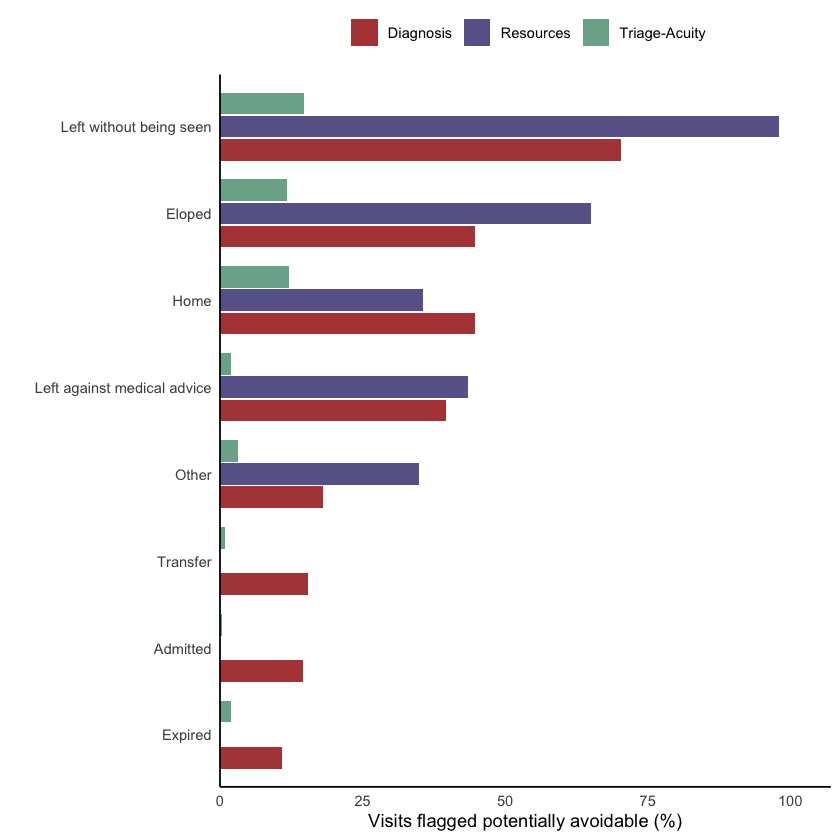

In [12]:
fig_1a_data <- ed_data |>
  group_by(disp_l) |>
  summarise(
    Diagnosis       = 100 * mean(nyu == 1),
    Resources       = 100 * mean(res == 1),
    `Triage-Acuity` = 100 * mean(acuity_out == 1),
    .groups = "drop"
  ) |>
  pivot_longer(-disp_l, names_to = "algorithm", values_to = "pct") |>
  mutate(
    disp_l    = fct_reorder(disp_l, pct, .fun = max),
    algorithm = factor(algorithm, levels = c("Diagnosis", "Resources", "Triage-Acuity"))
  )

figure_1a <- fig_1a_data |>
  ggplot(aes(x = disp_l, y = pct, fill = algorithm)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  coord_flip() +
  scale_y_continuous(limits = c(0, 105), expand = expansion(mult = c(0, 0.02))) +
  scale_fill_manual(values = jama_palette[c(4, 6, 5)]) +
  labs(x = "", y = "Visits flagged potentially avoidable (%)", fill = "") +
  fig_theme +
  theme(legend.position = "top")

figure_1a

## Figure 1B

The acuity-stratified version. I drop cells with fewer than 30 visits - ESI 1 contains a single left-without-being-seen visit and says nothing.

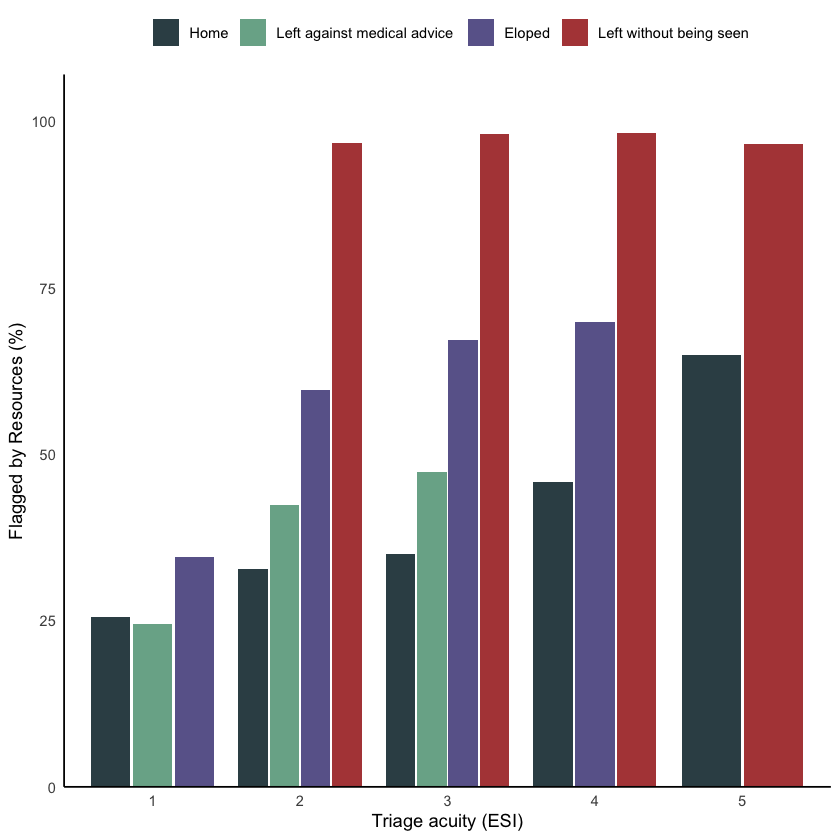

In [13]:
fig_1b_data <- ed_data |>
  filter(disposition %in% c("HOME", lbcc_disp)) |>
  group_by(disp_l, acuity) |>
  summarise(N = n(), pct = 100 * mean(res == 1), .groups = "drop") |>
  filter(N >= 30) |>
  mutate(
    disp_l = factor(
      disp_l,
      levels = c("Home", "Left against medical advice", "Eloped", "Left without being seen")
    ),
    acuity = factor(acuity)
  )

figure_1b <- fig_1b_data |>
  ggplot(aes(x = acuity, y = pct, fill = disp_l)) +
  geom_col(position = position_dodge(width = 0.85), width = 0.8) +
  scale_y_continuous(limits = c(0, 105), expand = expansion(mult = c(0, 0.02))) +
  scale_fill_manual(values = jama_palette[c(1, 5, 6, 4)]) +
  labs(
    x    = "Triage acuity (ESI)",
    y    = "Flagged by Resources (%)",
    fill = ""
  ) +
  fig_theme +
  theme(legend.position = "top")

figure_1b

## Join

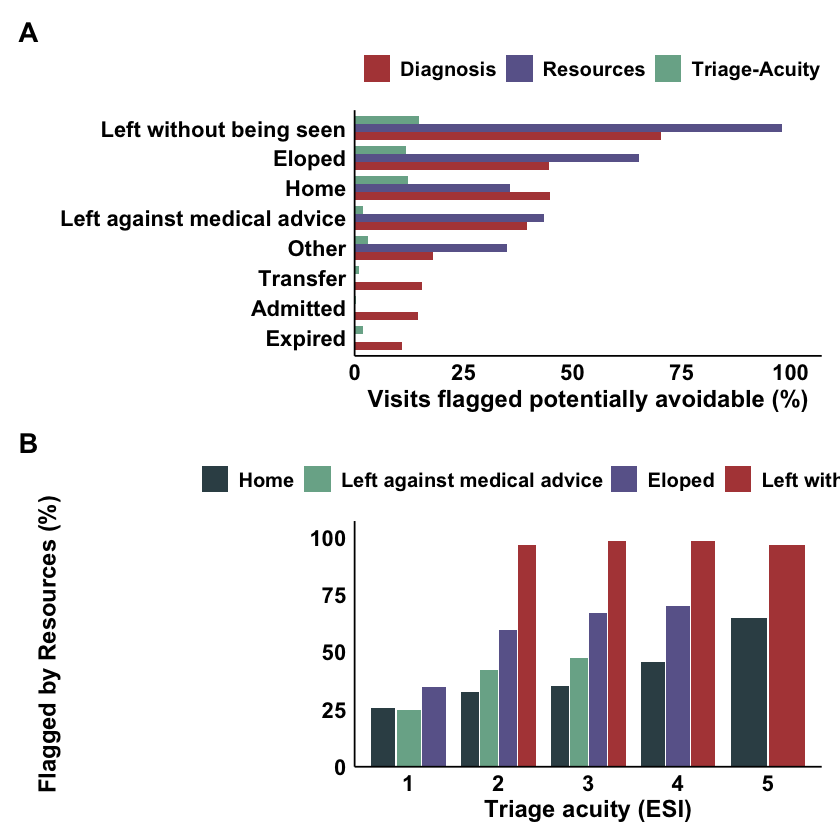

In [14]:
Figure_1 <- figure_1a / figure_1b +
  plot_annotation(
    tag_levels = "A"
  )&
  theme(
    plot.tag    = element_text(size = rel(1.5), colour = "black", face = "bold"),
    axis.text   = element_text(size = rel(1.2), colour = "black", face = "bold"),
    axis.title  = element_text(size = rel(1.3), colour = "black", face = "bold"),
    legend.text = element_text(size = rel(1.1), colour = "black", face = "bold")
  )

ggsave("s4_figure_1.png", plot = Figure_1, device = "png", width = 13, height = 11, units = "in", dpi = 600)
ggsave("s4_figure_1.svg", plot = Figure_1, device = "svg", width = 13, height = 11, units = "in")
ggsave("s4_figure_1.pdf", plot = Figure_1, device = "pdf", width = 13, height = 11, units = "in")

Figure_1


# Are these patients different?

If the group that left early were just a milder slice of the home discharges, the flag would at least be pointing at something real. Compare them against completed home discharges.

The groups are large enough that everything is significant, so I use standardised mean differences instead, with the conventional |SMD| > 0.1 threshold.

In [15]:
smd_cont <- function(x1, x2) {
  m1 <- mean(x1, na.rm = TRUE); m2 <- mean(x2, na.rm = TRUE)
  s1 <- sd(x1,   na.rm = TRUE); s2 <- sd(x2,   na.rm = TRUE)
  (m1 - m2) / sqrt((s1^2 + s2^2) / 2)
}

smd_prop <- function(p1, p2) (p1 - p2) / sqrt((p1 * (1 - p1) + p2 * (1 - p2)) / 2)

# star marks |SMD| > 0.1
smd_fmt <- function(s) sprintf("%+.3f%s", s, ifelse(abs(s) > 0.1, " *", ""))

home_d <- ed_data |>
  filter(disposition == "HOME") |>
  mutate(race5 = case_when(
    str_detect(race, "WHITE")    ~ "White",
    str_detect(race, "BLACK")    ~ "Black",
    str_detect(race, "HISPANIC") ~ "Hispanic/Latino",
    str_detect(race, "ASIAN")    ~ "Asian",
    TRUE                         ~ "Other"
  ))

lbcc_d <- ed_data |>
  filter(lbcc) |>
  mutate(race5 = case_when(
    str_detect(race, "WHITE")    ~ "White",
    str_detect(race, "BLACK")    ~ "Black",
    str_detect(race, "HISPANIC") ~ "Hispanic/Latino",
    str_detect(race, "ASIAN")    ~ "Asian",
    TRUE                         ~ "Other"
  ))

dama_d <- lbcc_d |> filter(disposition == "LEFT AGAINST MEDICAL ADVICE")

print(paste("Home", nrow(home_d), "| Left before completing care", nrow(lbcc_d),
            "| Against medical advice", nrow(dama_d)))

[1] "Home 121407 | Left before completing care 5266 | Against medical advice 756"


In [16]:
cont_row <- function(v, label, dp = 1) {
  f <- function(d) sprintf(paste0("%.", dp, "f (%.", dp, "f)"),
                           mean(d[[v]], na.rm = TRUE), sd(d[[v]], na.rm = TRUE))
  tibble(
    Variable                      = label,
    Home                          = f(home_d),
    `Left before completing care` = f(lbcc_d),
    `SMD (left early)`            = smd_fmt(smd_cont(lbcc_d[[v]], home_d[[v]])),
    `Against medical advice`      = f(dama_d),
    `SMD (AMA)`                   = smd_fmt(smd_cont(dama_d[[v]], home_d[[v]]))
  )
}

bin_row <- function(f, label) {
  g <- function(d) {
    p <- mean(f(d))
    sprintf("%s (%.1f%%)", format(sum(f(d)), big.mark = ",", trim = TRUE), 100 * p)
  }
  pH <- mean(f(home_d)); pL <- mean(f(lbcc_d)); pA <- mean(f(dama_d))
  tibble(
    Variable                      = label,
    Home                          = g(home_d),
    `Left before completing care` = g(lbcc_d),
    `SMD (left early)`            = smd_fmt(smd_prop(pL, pH)),
    `Against medical advice`      = g(dama_d),
    `SMD (AMA)`                   = smd_fmt(smd_prop(pA, pH))
  )
}

compare_tab <- bind_rows(
  cont_row("age", "Age, mean (SD)", 1),
  bin_row(\(d) d$gender == "F", "Female"),
  bin_row(\(d) d$race5 == "White", "Race: White"),
  bin_row(\(d) d$race5 == "Black", "Race: Black"),
  bin_row(\(d) d$race5 == "Hispanic/Latino", "Race: Hispanic/Latino"),
  bin_row(\(d) d$race5 == "Asian", "Race: Asian"),
  bin_row(\(d) d$race5 == "Other", "Race: Other/unknown"),
  cont_row("acuity", "Triage ESI, mean (SD)", 2),
  cont_row("length_of_stay", "Length of stay, min, mean (SD)", 1)
)

compare_tab |> kable()

compare_tab |>
  gt() |>
  tab_footnote(
    footnote  = "Standardised mean difference against home discharges; * marks |SMD| > 0.1.",
    locations = cells_column_labels(columns = c(`SMD (left early)`, `SMD (AMA)`))
  ) |>
  gtsave(filename = "s4_table_3.docx")




|Variable                       |Home           |Left before completing care |SMD (left early) |Against medical advice |SMD (AMA) |
|:------------------------------|:--------------|:---------------------------|:----------------|:----------------------|:---------|
|Age, mean (SD)                 |43.1 (19.1)    |42.5 (17.5)                 |-0.030           |50.3 (18.2)            |+0.388 *  |
|Female                         |67,405 (55.5%) |2,726 (51.8%)               |-0.075           |367 (48.5%)            |-0.140 *  |
|Race: White                    |70,542 (58.1%) |2,210 (42.0%)               |-0.327 *         |473 (62.6%)            |+0.091    |
|Race: Black                    |22,800 (18.8%) |899 (17.1%)                 |-0.045           |139 (18.4%)            |-0.010    |
|Race: Hispanic/Latino          |9,605 (7.9%)   |346 (6.6%)                  |-0.052           |36 (4.8%)              |-0.130 *  |
|Race: Asian                    |7,977 (6.6%)   |197 (3.7%)               

Patients leaving against medical advice are older (50.3 against 43.1) and *more* urgent at
triage, not less. That is the opposite of the group a low-resource-need measure is supposed to
be picking out.


The pooled group looks like it has a large excess of other/unknown race. It doesn't - that is a registration artefact. If a patient leaves before registration is completed, race never gets recorded.

In [17]:
tibble(
  Group = c("Home", "Left before completing care", "Against medical advice"),
  `Race recorded as UNKNOWN (%)` = sprintf(
    "%.2f",
    100 * c(mean(home_d$race == "UNKNOWN"),
            mean(lbcc_d$race == "UNKNOWN"),
            mean(dama_d$race == "UNKNOWN"))
  )
) |> kable()



|Group                       |Race recorded as UNKNOWN (%) |
|:---------------------------|:----------------------------|
|Home                        |0.53                         |
|Left before completing care |23.85                        |
|Against medical advice      |3.17                         |

23.9% against 0.5%. That is the whole of the difference, so I won't read anything into it.

Complaint cluster and ICD chapter next. Chief complaint is used by none of the three algorithms, so the clusters are the cleanest comparison available here; the primary discharge code feeds the Diagnosis algorithm, so read that half more carefully.

In [18]:
cluster_labels <- c(
  "Lower back pain", "Influenza like illness",
  "Vehicle collision + Altered mental status", "Chest pain + dyspnea",
  "Shortness breath", "Abdomen pain", "Leg + knee pain",
  "Wound evaluation", "Alcohol intoxication", "Nausea vomiting",
  "Suicidal ideation", "Fall transfer"
)

home_d <- home_d |> mutate(cluster_l = cluster_labels[cluster + 1])
lbcc_d <- lbcc_d |> mutate(cluster_l = cluster_labels[cluster + 1])
dama_d <- dama_d |> mutate(cluster_l = cluster_labels[cluster + 1])

top_k <- function(d, col, k = 5) {
  props <- sort(prop.table(table(d[[col]])), decreasing = TRUE)
  nms   <- names(props)[seq_len(min(k, length(props)))]
  ref   <- prop.table(table(home_d[[col]]))
  tibble(
    Category      = nms,
    `% of group`  = sprintf("%.1f", 100 * as.numeric(props[nms])),
    `% of home`   = sprintf("%.1f", 100 * as.numeric(ref[nms])),
    SMD           = unname(vapply(nms, \(nm) smd_fmt(smd_prop(mean(d[[col]] == nm, na.rm = TRUE),
                                                               mean(home_d[[col]] == nm, na.rm = TRUE))), ""))
  )
}

case_tab <- bind_rows(
  top_k(lbcc_d, "cluster_l")   |> mutate(Comparison = "Complaint cluster, left before completing care"),
  top_k(dama_d, "cluster_l")   |> mutate(Comparison = "Complaint cluster, against medical advice"),
  top_k(lbcc_d, "icd_chapter") |> mutate(Comparison = "ICD chapter, left before completing care"),
  top_k(dama_d, "icd_chapter") |> mutate(Comparison = "ICD chapter, against medical advice")
) |>
  select(Comparison, Category, `% of group`, `% of home`, SMD)

case_tab |> kable()

case_tab |>
  group_by(Comparison) |>
  gt() |>
  tab_footnote(
    footnote  = "Standardised mean difference against home discharges; * marks |SMD| > 0.1.",
    locations = cells_column_labels(columns = SMD)
  ) |>
  gtsave(filename = "s4_table_4.docx")



|Comparison                                     |Category                                                       |% of group |% of home |SMD      |
|:----------------------------------------------|:--------------------------------------------------------------|:----------|:---------|:--------|
|Complaint cluster, left before completing care |Wound evaluation                                               |16.2       |18.4      |-0.057   |
|Complaint cluster, left before completing care |Vehicle collision + Altered mental status                      |13.6       |13.5      |+0.004   |
|Complaint cluster, left before completing care |Abdomen pain                                                   |13.1       |10.9      |+0.065   |
|Complaint cluster, left before completing care |Lower back pain                                                |10.8       |10.9      |-0.005   |
|Complaint cluster, left before completing care |Chest pain + dyspnea                                           |9.9

The complaint side is the honest one and it does not look like a mild group - patients leaving against medical advice concentrate in chest pain + dyspnoea (18.8% against 8.6% of home) and shortness of breath (12.7% against 6.7%). Those are not presentations a resource measure should be calling avoidable.

The ICD side shows a heavy shift into ill-defined conditions, which is what an interrupted work-up produces. Worth flagging that this is the input to the Diagnosis algorithm, so the two are not independent - the same interruption that empties the medication field also pushes the coded diagnosis towards the codes the NYU lookup treats as non-emergent.

# What it costs the estimate

Last thing. Add the three departure dispositions to the Resources exclusion list and recompute. Sample and the other two algorithms untouched, so this is like for like.

In [19]:
res_adj   <- ifelse(ed_data$lbcc, 0L, as.integer(ed_data$res))
n_any     <- sum(ed_data$nyu == 1 | ed_data$res == 1 | ed_data$acuity_out == 1)
n_res_adj <- sum(res_adj)
n_any_adj <- sum(ed_data$nyu == 1 | res_adj == 1 | ed_data$acuity_out == 1)

np <- function(n, den) sprintf("%s (%.1f%%)", format(n, big.mark = ",", trim = TRUE), 100 * n / den)

impact_tab <- tibble(
  Scenario = c(
    "As analysed",
    "Left before completing care made ineligible for Resources"
  ),
  Diagnosis       = c(np(n_nyu, n_tot), np(n_nyu, n_tot)),
  Resources       = c(np(n_res, n_tot), np(n_res_adj, n_tot)),
  `Triage-Acuity` = c(np(n_acu, n_tot), np(n_acu, n_tot)),
  `Flagged by at least one` = c(np(n_any, n_tot), np(n_any_adj, n_tot))
)

impact_tab |> kable()

impact_tab |>
  gt() |>
  tab_footnote(
    footnote  = paste0("Denominator ", format(n_tot, big.mark = ","), " visits in both rows."),
    locations = cells_column_labels(columns = Scenario)
  ) |>
  gtsave(filename = "s4_table_5.docx")



|Scenario                                                  |Diagnosis      |Resources      |Triage-Acuity |Flagged by at least one |
|:---------------------------------------------------------|:--------------|:--------------|:-------------|:-----------------------|
|As analysed                                               |68,173 (33.9%) |48,181 (24.0%) |15,716 (7.8%) |100,568 (50.0%)         |
|Left before completing care made ineligible for Resources |68,173 (33.9%) |44,060 (21.9%) |15,716 (7.8%) |99,081 (49.3%)          |

In [20]:
print(paste0(
  "Resources loses ", format(n_res - n_res_adj, big.mark = ","),
  " visits, but the union only loses ", format(n_any - n_any_adj, big.mark = ","),
  " - because ",
  format(sum(ed_data$lbcc & ed_data$res == 1 & (ed_data$nyu == 1 | ed_data$acuity_out == 1)), big.mark = ","),
  " of them were already flagged by Diagnosis or Triage-Acuity as well."
))

[1] "Resources loses 4,121 visits, but the union only loses 1,487 - because 2,634 of them were already flagged by Diagnosis or Triage-Acuity as well."


Resources falls from 48,181 (24.0%) to 44,060 (21.9%), and flagged-by-at-least-one from 100,568 (50.0%) to 99,081 (49.3%). A small move, because most of those visits are caught by another algorithm anyway.

So the headline survives, but the reading of the Resources flag does not. It cannot distinguish a visit that needed few resources from one where the patient left before receiving any, and about one in twelve of the visits it flags is a patient who never completed care. That bounds how far the Resources estimate can be taken - and it means the flag rate will track a department's walkout rate, which has nothing to do with avoidability.